In [540]:
# Import basic packages
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

In [541]:
# Read CSV file
df_raw = pd.read_csv('ims_setup_project02.csv')

In [542]:
# Make a copy and convert columns to numeric
df = df_raw.copy()
for columns in df.columns:
    df[columns] = pd.to_numeric(df[columns], errors='coerce')

In [543]:
# Grouped data frame
df_groupby = df.groupby(["rear_wing_angle_deg","rear_ride_height_mm"], as_index = False).agg(
    mean_sector_3_time_s = ("sector_3_time_s","mean"), std_sector_3_time_s = ("sector_3_time_s","std"), valid_laps = ("lap","count") )

In [544]:
# Save new grouped data frame into CSV
df_groupby.to_csv("mgfreita_pr03_grouped.csv", index= False)

In [545]:
# Sort and reindex grouped dataframe by first rear wing, then rear ride height values. Rename the index column as setup_id
df_grouped = df_groupby.sort_values(by=['rear_wing_angle_deg', 'rear_ride_height_mm']).reset_index()
df_grouped = df_grouped.rename(columns={'index': 'setup_id'})

In [546]:
# Split the grouped dataframe into testing and validation with 25% testing size
from sklearn.model_selection import train_test_split
df_train, df_test = train_test_split(df_grouped, test_size=0.25, random_state=42)

In [547]:
# Size of the splitting
print("Number of unique training setups", len(df_train))
print("Number of unique testing setups", len(df_test))

Number of unique training setups 20
Number of unique testing setups 7


The split between training and test should occur after grouping to avoid data leakage, otherwise the same setup in different runs can be used for both training and validation.

In [548]:
# Create numpy matrix for the input variables and numpy array for the response variable
X_train = df_train[['rear_wing_angle_deg', 'rear_ride_height_mm']].to_numpy()
X_test = df_test[['rear_wing_angle_deg', 'rear_ride_height_mm']].to_numpy()
y_train = df_train[['mean_sector_3_time_s']].to_numpy()
y_test = df_test[['mean_sector_3_time_s']].to_numpy()

In [549]:
# Minimum and maximum bounds across each column of X_train
X_min = X_train.min(axis=0)
X_max = X_train.max(axis=0)

In [550]:
# Print bounds
print(X_min)
print(X_max)

[ 5 35]
[13 45]


Indeed, the bounds for the rear wing angle is 5-13 deg and for the rear ride height is 35-45 mm

In [551]:
# Normalized X_train and X_test
X_train_normalized = (X_train - X_min)/(X_max-X_min)
X_test_normalized = (X_test-X_min)/(X_max-X_min)

In [552]:
# Define norm function and RBF kernel phi
def norm(a,b):
    return np.sqrt(np.dot(a-b,a-b))
def phi(a,b,sigma):
    return np.exp(-norm(a,b)**2/(2*sigma**2))

In [553]:
# Define RBF matrix
def rbf_matrix(A,B,sigma):
    matrix = np.zeros((len(A),len(B)))
    for i in range(len(A)):
        for j in range(len(B)):
            matrix[i, j] = phi(A[i], B[j], sigma)   # Entry (i,j) computes the kernel between row i of A and row j of B
    return matrix

In [654]:
# Define Gram matrix on the normalized X_train
Gram_matrix =  rbf_matrix(X_train_normalized,X_train_normalized,sigma = 0.2)
print("Gram matrix shape \n", Gram_matrix.shape)
print("The diagonal is indeed 1: \n", np.diagonal(Gram_matrix))

Gram matrix shape 
 (20, 20)
The diagonal is indeed 1: 
 [1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


In [555]:
# Return coefficient vector of RBF fitting
def fit_rbf(X,y,sigma,lam):
    Gram_matrix = rbf_matrix(X,X,sigma)
    I = np.eye(len(Gram_matrix))
    return np.linalg.solve(Gram_matrix+lam*I,y)

In [556]:
# Return predicted response
def predict_rbf(X_new, centers, b, sigma):
    Gram_matrix = rbf_matrix(X_new, centers, sigma)
    return Gram_matrix @ b   # Vector ouput. Entry i gives the sum of b_j phi(x_i, c_j) for j in centers.

In [557]:
# Fit the vector of coefficients
b_fit = fit_rbf(X_train_normalized, y_train, sigma = 0.2, lam  = 0.01)

In [558]:
# Return vector of predicted response for each setup configuration of X_test, using centers of X_train
yhat_train = predict_rbf(X_train_normalized, X_train_normalized , b_fit , sigma = 0.2)

In [559]:
# Checking predictions against Scipy
sigma = 0.2
lam = 0.01

from scipy.interpolate import RBFInterpolator
model = RBFInterpolator(X_train_normalized, y_train, kernel = "gaussian", epsilon = 1/(np.sqrt(2)*sigma), smoothing = lam, degree = -1)
yhat_train_scipy = model(X_train_normalized)

In [560]:
# Absolute difference between predicted y_test and predicted y_test from scipy
delta_train = np.abs(yhat_train - yhat_train_scipy)
print(delta_train.max())

1.4210854715202004e-14


In [561]:
# Checking absolute difference on additional five setup configurations
setup = np.array([[6,38],[7.5,39], [8,42.8], [11.3, 44.8], [10.6, 41.1]])
setup_normalized = (setup-X_min)/(X_max-X_min)
yhat_setup = predict_rbf(setup_normalized, X_train_normalized, b_fit, sigma = 0.2)
yhat_setup_scipy = model(setup_normalized)
delta_setup = np.abs(yhat_setup - yhat_setup_scipy)
print(delta_setup.max())


1.4210854715202004e-14


When checking the fitted model against scipy, in all case scenarios the maximum abosolute difference is irrelevant, i.e., smaller than e-6.


In [562]:
# Obtain RMSE for the training set of the fitted model
RMSE_train = np.sqrt(np.mean((y_train - yhat_train)**2))
print("The training RMSE is", RMSE_train)

The training RMSE is 0.2533624196554872


In the Gaussian RBF model, sigma and lambda are the hyperparameters that are chosen before fitting the model, while the vector of coefficient is the only fitted parameter.

In [563]:
# Return vector of predictions after perfoming LOOCV
def loocv_rbf(X,y,sigma,lam):
  predictions = np.zeros(len(X))
  for i in range(len(X)):
    X_omit  = np.delete(X, i , axis = 0)
    y_omit = np.delete(y, i ,axis = 0)
    b_omit = fit_rbf(X_omit, y_omit, sigma, lam)
    yhat_omit = predict_rbf(X[i:i+1], X_omit, b_omit, sigma)   # Predict the i-th response
    predictions[i] = yhat_omit.item()
  return predictions.reshape(-1,1)

In [564]:
# Compute PRESS and RMSE from LOOCV
yhat_cv = loocv_rbf(X_train_normalized, y_train, sigma = 0.2, lam = 0.01)
PRESS = np.sum((y_train - yhat_cv)**2)
RMSE_CV = np.sqrt(np.mean((y_train - yhat_cv)**2))
print("The PRESS is", PRESS)
print("The CV RMSE is", RMSE_CV)

The PRESS is 606.2052237305064
The CV RMSE is 5.505475564065771


The defaul training RMSE is 0.2534 s  and the LOOCV RMSE is 5.5055 s. These values are quite distinct, showing that the model performs better against data used to train it for the choice of standard sigma and lambda values.

In [565]:
# Computing PRESS and RMSE for different hyperparameters
sigma_values = np.logspace(-1.3,0,15)
lam_values = np.logspace(-8,0,9)

results = []
for sigma in sigma_values:
  for lam in lam_values:
    try:
      yhat_grid = loocv_rbf(X_train_normalized, y_train, sigma = sigma, lam = lam)
      PRESS_grid = np.sum((y_train - yhat_grid)**2)
      RMSE_grid = np.sqrt(np.mean((y_train - yhat_grid)**2))
      status = "ok"
    except np.linalg.LinAlgError:
      press = np.inf
      rmse_cv = np.inf
      status = "failed"
    results.append({ "sigma": sigma,"lam": lam,"PRESS": PRESS_grid,"RMSE_CV": RMSE_grid,"status": status})

In [566]:
# Create a data frame with PRESS and RMSE_CV for each pair of sigma and lambda values
df_cv_search = pd.DataFrame(results)

In [567]:
# Locate and display the best 5 pairs and compute the percentage reduction
top_five = df_cv_search.sort_values("RMSE_CV").head(5).copy()
top_five['%'] = (top_five['RMSE_CV']-RMSE_train)*100/RMSE_train
best = top_five.iloc[0]
display("Top five combinations", top_five[['sigma', 'lam', 'RMSE_CV', '%']])
display('Best combination', best[['sigma', 'lam']])

'Top five combinations'

,sigma,lam,RMSE_CV,%
108,0.652057,1.000000e-08,0.079407,-68.658588
117,0.807501,1.000000e-08,0.086617,-65.812944
109,0.652057,1.000000e-07,0.088006,-65.264679
129,1.000000,1.000000e-05,0.090021,-64.469361
99,0.526537,1.000000e-08,0.092574,-63.461950


'Best combination'

,108
sigma,0.652057
lam,0.0


The selected best combination has a negative reduction, meaning that the RMSE_CV number is smaller than the training RMSE number.

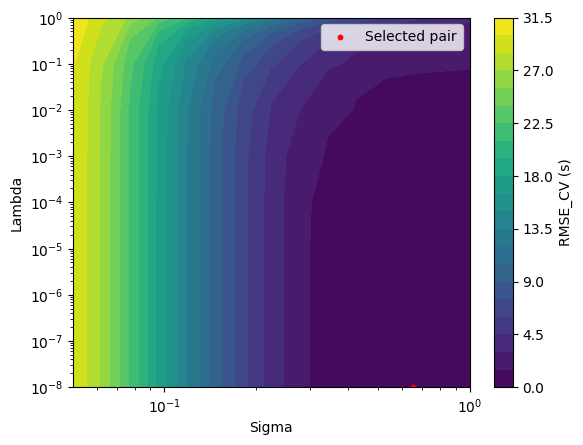

In [627]:
# Contour plot of RMSE as a function of sigma and lamda
RMSE_plot = df_cv_search["RMSE_CV"].to_numpy().reshape(len(sigma_values), len(lam_values)).T
contour = plt.contourf(sigma_values, lam_values, RMSE_plot, levels=20)
plt.scatter(best["sigma"], best["lam"], color="red", marker="o", s=10, label="Selected pair")
plt.xscale("log")
plt.yscale("log")
plt.xlabel("Sigma")
plt.ylabel("Lambda")
plt.colorbar(contour, label="RMSE_CV (s)")
plt.legend()
plt.show()

From the contour plot, we can see that the selected pair is on the search boundary, as the value of lambda is essentially zero. The low-error region is arc-shaped (in log scale) and relatively broad.

In [569]:
# For the selected optimal hyperparameters, record and display the setup, predicted vs actual lap times and residuals for every LOO
sigma_opt = best["sigma"]
lam_opt = best["lam"]
results_cv_opt = []

for i in range(len(X_train_normalized)):
    X_omit  = np.delete(X_train_normalized, i , axis = 0)
    y_omit = np.delete(y_train, i ,axis = 0)
    b_omit = fit_rbf(X_omit, y_omit, sigma = sigma_opt, lam = lam_opt)
    yhat_omit = predict_rbf(X_train_normalized[i:i+1], X_omit, b_omit, sigma = sigma_opt)
    results_cv_opt.append({"setup_id": df_train.iloc[i]["setup_id"],
                           "rear_wing_angle_deg": df_train.iloc[i]["rear_wing_angle_deg"],
                           "rear_ride_height_mm": df_train.iloc[i]["rear_ride_height_mm"],
                           "actual_time_s": df_train.iloc[i]["mean_sector_3_time_s"],
                           "predicted_time_s": yhat_omit.item(),
                           "residual_s": df_train.iloc[i]["mean_sector_3_time_s"] - yhat_omit.item(),
                           "abs_residual_s": np.abs(df_train.iloc[i]["mean_sector_3_time_s"] - yhat_omit.item())})

loocv_opt = pd.DataFrame(results_cv_opt)
loocv_opt = loocv_opt.sort_values(by="abs_residual_s")
display(loocv_opt)

,setup_id,rear_wing_angle_deg,rear_ride_height_mm,actual_time_s,predicted_time_s,residual_s,abs_residual_s
0,17.0,10.0,45.0,31.44488,31.440167,0.004713,0.004713
14,20.0,11.0,45.0,31.43942,31.444195,-0.004775,0.004775
11,23.0,12.0,45.0,31.59506,31.585813,0.009247,0.009247
7,15.0,10.0,35.0,31.32624,31.316919,0.009321,0.009321
17,14.0,9.0,45.0,31.54258,31.552755,-0.010175,0.010175
1,12.0,9.0,35.0,31.44076,31.452658,-0.011898,0.011898
12,18.0,11.0,35.0,31.28502,31.305592,-0.020572,0.020572
19,6.0,7.0,35.0,32.03248,32.004831,0.027649,0.027649
15,7.0,7.0,40.0,31.86244,31.890428,-0.027988,0.027988
5,5.0,6.0,45.0,32.44690,32.410609,0.036291,0.036291


For the optimal hyperparameters, the setup configuration with smallest absolute residual is rear wing angle 10 deg, rear ride height 45 mm. The setup with the largest absolute residual is rear wing angle 13 deg and rear ride height 35 mm.

In [570]:
# Function that construct design matrix of quadractic model
def design(Z):
        z1, z2 = Z[:,0], Z[:,1]
        return np.column_stack((np.ones(len(z1)), z1, z2, z1**2, z2**2, z1*z2))

In [608]:
# Fit quadractic regression and compute predicted response in LOO
def loocv_quad(X,y):
  predictions = np.zeros(len(X))
  for i in range(len(X)):
    X_omit = np.delete(X, i , axis = 0)
    y_omit = np.delete(y, i ,axis = 0)
    design(X_omit)
    b_omit = np.linalg.pinv(design(X_omit))@ y_omit
    yhat_omit = design(X[i:i+1])@ b_omit
    predictions[i]  = yhat_omit.item()
  return predictions.reshape(-1,1)

In [572]:
# Fit and predict lap time with quadratic model
def predict_quad(X,y, X_new):
  b = np.linalg.pinv(design(X))@ y
  return design(X_new)@b

In [573]:
# Compute RMSE for LOOCV in the quadractic model
RMSE_CV_quad = np.sqrt(np.mean((y_train - loocv_quad(X_train_normalized, y_train))**2))
print("For the quadratic model the RMSE for the LOOCV is", RMSE_CV_quad)

For the quadratic model the RMSE for the LOOCV is 0.02652942826888068


In [574]:
# Display RMSE_CV for the default RBF, the tuned RBF and quadratic model
pd.DataFrame({"model": ["default_rbf", "tuned_rbf", "quadratic"], "RMSE_CV_s": [RMSE_CV, best["RMSE_CV"], RMSE_CV_quad]})

,model,RMSE_CV_s
0,default_rbf,5.505476
1,tuned_rbf,0.079407
2,quadratic,0.026529


Surprisingly the quadratic model has the smallest RMSE_CV number.

In [575]:
# Predicting results from test configurations with the default RBF
b_default = fit_rbf(X_train_normalized, y_train, sigma = 0.2, lam = 0.01)
yhat_test_default = predict_rbf(X_test_normalized, X_train_normalized , b_default , sigma = 0.2)

In [576]:
# Test RMSE, MAE and R2 for the default RBF
RMSE_test_default = np.sqrt(np.mean((y_test - yhat_test_default)**2))
MAE_test_default = np.mean(np.abs(y_test - yhat_test_default))
R2_test_default = 1 - np.sum((y_test - yhat_test_default)**2)/np.sum((y_test - np.mean(y_test))**2)

In [577]:
# Data frame with training and testing evaluation for the default RBF
rbf_default = pd.DataFrame({"model": "default_rbf", "sigma": [0.2], "lam":[0.01], "train_RMSE_s": RMSE_train,
                            "RMSE_CV_s": RMSE_CV, "test_RMSE_s": RMSE_test_default, "test_MAE_s": MAE_test_default, "test_R2": R2_test_default})


In [628]:
# Predicting results from test configurations with the tuned RBF
b_tuned = fit_rbf(X_train_normalized, y_train, sigma = sigma_opt, lam = lam_opt)
yhat_test_tuned = predict_rbf(X_test_normalized, X_train_normalized , b_tuned , sigma = sigma_opt)

In [579]:
# RMSE for training configurations with the tuned RBF
yhat_train_tuned = predict_rbf(X_train_normalized, X_train_normalized, b_tuned, sigma = best["sigma"])
RMSE_train_tuned = np.sqrt(np.mean((y_train - yhat_train_tuned)**2))

In [580]:
# Test RMSE, MAE and R2 for the tuned RBF
RMSE_test_tuned = np.sqrt(np.mean((y_test - yhat_test_tuned)**2))
MAE_test_tuned = np.mean(np.abs(y_test - yhat_test_tuned))
R2_test_tuned = 1 - np.sum((y_test - yhat_test_tuned)**2)/np.sum((y_test - np.mean(y_test))**2)

In [581]:
# Data frame with training and testing evaluation for the tuned RBF
rbf_tuned = pd.DataFrame({"model": "tuned_rbf", "sigma": [best["sigma"]], "lam":[best["lam"]], "train_RMSE_s": RMSE_train_tuned,
                            "RMSE_CV_s": best["RMSE_CV"], "test_RMSE_s": RMSE_test_tuned, "test_MAE_s": MAE_test_tuned, "test_R2": R2_test_tuned})

In [582]:
# Predicting results from test configurations with quadratic model
yhat_test_quad = predict_quad(X_train_normalized, y_train, X_test_normalized)

In [583]:
# RMSE for training configurations with the quadratic RBF
yhat_train_quad = predict_quad(X_train_normalized, y_train, X_train_normalized)
RMSE_train_quad = np.sqrt(np.mean((y_train - yhat_train_quad)**2))

In [584]:
# Test RMSE, MAE and R2 for the quadratic model
RMSE_test_quad = np.sqrt(np.mean((y_test - yhat_test_quad)**2))
MAE_test_quad = np.mean(np.abs(y_test - yhat_test_quad))
R2_test_quad = 1 - np.sum((y_test - yhat_test_quad)**2)/np.sum((y_test - np.mean(y_test))**2)

In [585]:
# Data frame with training and testing evaluation for the quadratic model
quad = pd.DataFrame({"model": "quadratic", "sigma" : [" "], "lam": [" "], "train_RMSE_s": RMSE_train_quad,
                     "RMSE_CV_s": RMSE_CV_quad, "test_RMSE_s": RMSE_test_quad, "test_MAE_s": MAE_test_quad, "test_R2": R2_test_quad})

In [586]:
# Concatenate the validation results for all three models
df_validation  = pd.concat([rbf_default, rbf_tuned, quad], ignore_index=True)
display(df_validation)

,model,sigma,lam,train_RMSE_s,RMSE_CV_s,test_RMSE_s,test_MAE_s,test_R2
0,default_rbf,0.2,0.01,0.253362,5.505476,3.169248,2.231456,-29.154571
1,tuned_rbf,0.652057,0.0,0.000774,0.079407,0.121868,0.086699,0.955412
2,quadratic,,,0.019241,0.026529,0.025850,0.018986,0.997994


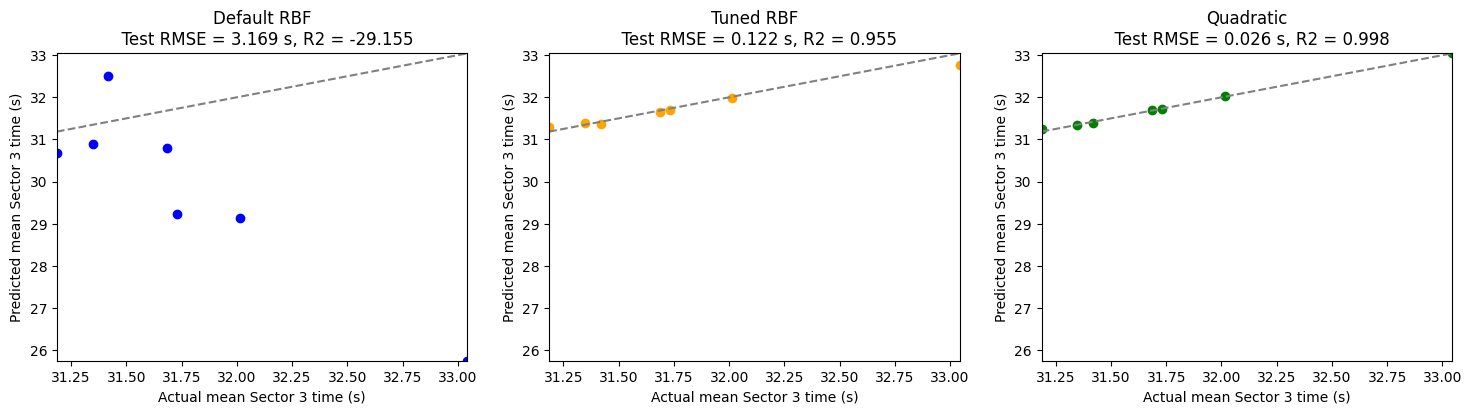

In [587]:
# Plot of actual vs predicted for each fitted model on testing data
fig, axes = plt.subplots(1, 3, figsize=(18, 4))

x_low, x_high = y_test.min(), y_test.max()
y_low = min(yhat_test_default.min(), yhat_test_tuned.min(), yhat_test_quad.min() )
y_high = max(yhat_test_default.max(), yhat_test_tuned.max(),yhat_test_quad.max())

plots = [(axes[0], yhat_test_default, "Default RBF",
     RMSE_test_default, R2_test_default, "blue"),
    (axes[1], yhat_test_tuned, "Tuned RBF",
     RMSE_test_tuned, R2_test_tuned, "orange"),
    (axes[2], yhat_test_quad, "Quadratic",
     RMSE_test_quad, R2_test_quad, "green")]


for ax, prediction, name, rmse, r2, color in plots:
    ax.scatter(y_test.ravel(), np.asarray(prediction).ravel(), color=color)
    ax.axline((0,0), slope=1, linestyle="--", color="grey")
    ax.set_xlabel("Actual mean Sector 3 time (s)")
    ax.set_xlim(x_low, x_high)
    ax.set_ylim(y_low, y_high)
    ax.set_ylabel("Predicted mean Sector 3 time (s)")
    ax.set_title(f"{name}\n  Test RMSE = {rmse:.3f} s, R2 = {r2:.3f}")

Tuning the RBF model clearly improved both the LOOCV and test RMSE numbers. The quadratic model is the model that has the best LOOCV RMSE as well as the best RMSE for training data across all three models. The testing RMSE and LOOCV RMSE numbers differ because these numbers are computed over testing and training datasets, respectively.

In [588]:
# Prepare grid for plotting tuned RBF surface
wing = df_grouped['rear_wing_angle_deg']
ride = df_grouped['rear_ride_height_mm']

wing_values = np.linspace(wing.min(), wing.max(), 101)
ride_values = np.linspace(ride.min(), ride.max(), 101)

wing_grid, ride_grid = np.meshgrid(wing_values, ride_values)

X_grid = np.column_stack((wing_grid.ravel(), ride_grid.ravel()))
X_grid_normalized = (X_grid - X_min) / (X_max - X_min)

In [589]:
# Fit the b coefficient using all configurations to predict lap times
X_all = df_grouped[['rear_wing_angle_deg', 'rear_ride_height_mm']].to_numpy()
X_all_normalized = (X_all - X_min) / (X_max - X_min)
y_all = df_grouped['mean_sector_3_time_s'].to_numpy()
b_all = fit_rbf(X_all_normalized, y_all, sigma = best["sigma"], lam = best["lam"])
yhat_grid = predict_rbf(X_grid_normalized, X_all_normalized, b_all, sigma = best["sigma"]).reshape(wing_grid.shape)

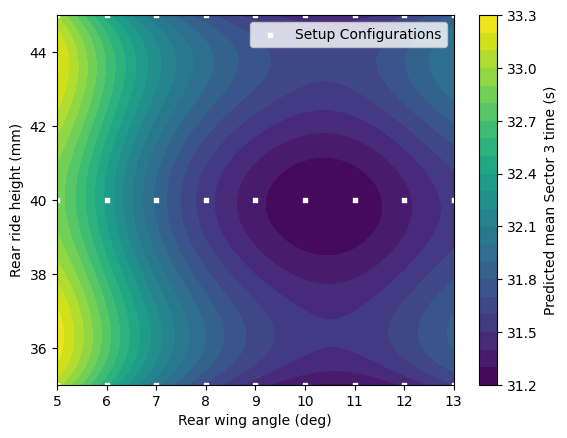

In [649]:
# Contour plot of tuned RBF response surface
contour_surf = plt.contourf(wing_grid, ride_grid, yhat_grid, levels=20)
plt.scatter(df_grouped['rear_wing_angle_deg'], df_grouped['rear_ride_height_mm'], marker = 's', s = 10, color = 'white', label = 'Setup Configurations')
plt.xlabel("Rear wing angle (deg)")
plt.ylabel("Rear ride height (mm)")
plt.colorbar(contour_surf, label="Predicted mean Sector 3 time (s)")
plt.legend()
plt.show()

In [626]:
# Positions of best and worst residual rows in the original LOOCV table
best_setup_id = loocv_opt.iloc[0]["setup_id"]
worst_setup_id = loocv_opt.iloc[-1]["setup_id"]

# Location of best and worst
worst_i = np.flatnonzero(df_train["setup_id"].to_numpy() == worst_setup_id)[0]
best_i = np.flatnonzero(df_train["setup_id"].to_numpy() == best_setup_id)[0]

In [633]:
# All training setups
b_all_train = fit_rbf(
    X_train_normalized, y_train, sigma_opt, lam_opt)
surface_all_train = predict_rbf(X_grid_normalized, X_train_normalized, b_all_train, sigma_opt).reshape(wing_grid.shape)

# Omit the worst setup
X_worst = np.delete(X_train_normalized, worst_i, axis=0)
y_worst = np.delete(y_train, worst_i, axis=0)
b_omit_worst = fit_rbf(X_worst, y_worst, sigma_opt, lam_opt)
surface_omit_worst = predict_rbf(X_grid_normalized, X_worst, b_omit_worst, sigma_opt).reshape(wing_grid.shape)

# Omit the best setup
X_best = np.delete(X_train_normalized, best_i, axis=0)
y_best = np.delete(y_train, best_i, axis=0)
b_omit_best = fit_rbf(X_best, y_best, sigma_opt, lam_opt)
surface_omit_best = predict_rbf(X_grid_normalized, X_best, b_omit_best, sigma_opt).reshape(wing_grid.shape)

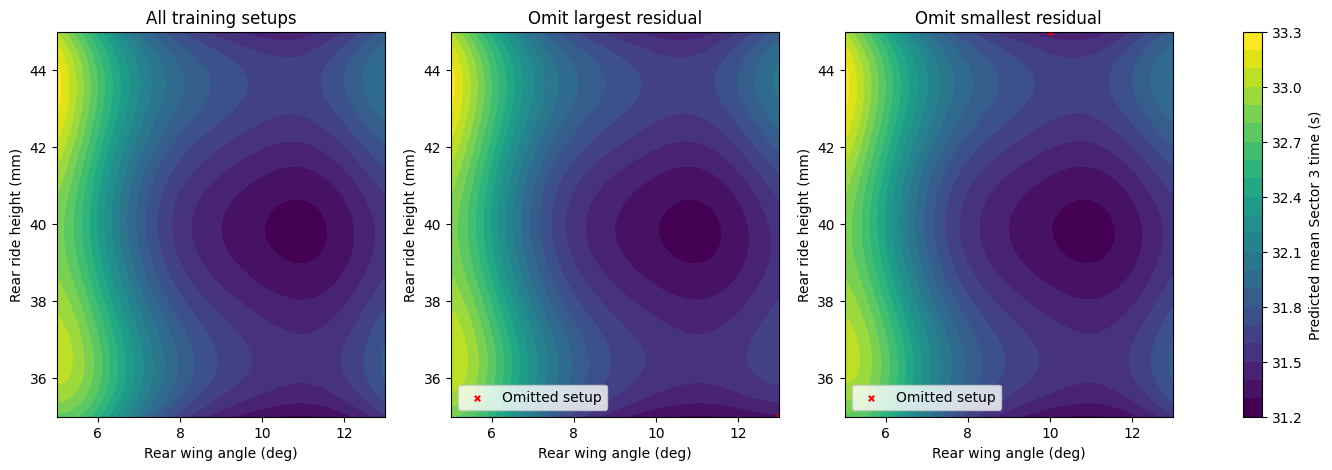

In [653]:
# Contour plot of tuned RBF response fitted using all training sets and omited best/worst
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

color_min = min(surface_all_train.min(),surface_omit_worst.min(),surface_omit_best.min())
color_max = max(surface_all_train.max(),surface_omit_worst.max(),surface_omit_best.max())

surfaces = [(axes[0], surface_all_train, "All training setups"),
    (axes[1], surface_omit_worst, "Omit largest residual"),
    (axes[2], surface_omit_best, "Omit smallest residual")]

for ax, surface, title in surfaces:
    contour = ax.contourf(wing_grid, ride_grid, surface,levels=20, vmin=color_min, vmax=color_max)
    ax.set_title(title)
    ax.set_xlabel("Rear wing angle (deg)")
    ax.set_ylabel("Rear ride height (mm)")

# Mark the omitted setups in their respective panels



axes[1].scatter(df_train.iloc[worst_i]["rear_wing_angle_deg"], df_train.iloc[worst_i]["rear_ride_height_mm"],marker="x", color="red", s=15, label="Omitted setup")
axes[1].legend(loc="lower left")



axes[2].scatter(df_train.iloc[best_i]["rear_wing_angle_deg"], df_train.iloc[best_i]["rear_ride_height_mm"],marker="x", color="red", s=15, label="Omitted setup")
axes[2].legend(loc="lower left")

fig.colorbar(contour, ax=axes, label="Predicted mean Sector 3 time (s)")
plt.show()

The parameter sigma controls how wide the gaussian curve is and the parameter lambda is the regularization parameter that help distinguish between the noise and underlying response. These parameters should not be obtained from solely minimizing training RMSE, since this may lead to overfit and perform poorly on unseen data. From this perspective, minimizing the LOOCV RMSE is more suitable, since it takes into account the error of predicting one unseen setup at the time. The selected pair that minimizes the LOOCV lies in the error region with the lowest value.

With respect to the three response surfaces, the surface obtained from omitting the setup with the largest residual is the one that differs the most from the surface obtained from all training setups. However, that difference is only locally around the omitted setup point.

I recommend the quadratic model for predicting mean Sector 3 time. It had the lowest LOOCV RMSE (0.0265 s) and test RMSE (0.0259 s), outperforming the tuned RBF on both cases. However, this evidence comes from one particular train/test split with only 27 setup configurations, another split could produce different measures.

The hyperparameters were also obtained from LOOCV out of a finite grid search. A different search range could produce another selected pair which could potentially outperform the quadractic model on the same train/test split or in a different one.

**PART 2 - Neural Networks**

In [591]:
# Read CSV file
df_laptime = pd.read_csv("simulated_laptime_data.csv")
df_laptime["row_id"] = df_laptime.index

In [592]:
# Basic statistics, shape and missing values
display("First five rows", df_laptime.head())
display("Basic statistics", df_laptime.describe())
display("Number of rows", df_laptime.shape[0])
display("Missing values", df_laptime.isna().sum())

'First five rows'

,fuel_kg,tire_age_laps,time_s,row_id
0,22.189146,7.846392,64.810266,0
1,29.207419,5.174721,65.917722,1
2,16.306554,10.407846,65.457985,2
3,29.178391,7.585621,65.778464,3
4,18.989303,9.723292,65.446376,4


'Basic statistics'

,fuel_kg,tire_age_laps,time_s,row_id
count,100.000000,100.000000,100.000000,100.000000
mean,22.209104,6.037854,65.101500,49.500000
std,4.615793,3.263998,0.964395,29.011492
min,14.093194,0.200674,63.108675,0.000000
25%,18.199190,3.511454,64.372019,24.750000
50%,22.223122,5.598018,65.020940,49.500000
75%,26.468585,9.008879,65.619956,74.250000
max,29.691795,11.988311,67.987389,99.000000


'Number of rows'

100

'Missing values'

,0
fuel_kg,0
tire_age_laps,0
time_s,0
row_id,0


In [593]:
# Split testing and training data
df_laptime_train, df_laptime_test = train_test_split(df_laptime, test_size = 0.25, random_state = 42)

In [594]:
# Create numpy arrays for training and testing data
X_train_nn = df_laptime_train[['fuel_kg', 'tire_age_laps']].to_numpy()
X_test_nn = df_laptime_test[['fuel_kg', 'tire_age_laps']].to_numpy()
y_train_nn = df_laptime_train['time_s'].to_numpy()
y_test_nn = df_laptime_test['time_s'].to_numpy()

# Compute column-wise minimum and maximum bounds
X_min_nn = X_train_nn.min(axis=0)
X_max_nn = X_train_nn.max(axis=0)

print("The fuel bounds are" , X_min_nn[0],X_max_nn[0])
print("The tire age laps are are" , X_min_nn[1], X_max_nn[1])

# Normalizing the data
X_train_nn_normalized = (X_train_nn - X_min_nn) / (X_max_nn - X_min_nn)
X_test_nn_normalized = (X_test_nn - X_min_nn) / (X_max_nn - X_min_nn)



The fuel bounds are 14.093193521727695 29.691795196819815
The tire age laps are are 0.2019274161625559 11.98831058788725


In [595]:
# Define MLPRegressor for both relu and tanh activations
from sklearn.neural_network import MLPRegressor
model_relu = MLPRegressor(hidden_layer_sizes = (20,20),
                          activation = 'relu',
                          solver = "lbfgs", alpha = 0.1,
                          max_iter = 5000, random_state = 1)
model_tanh = MLPRegressor(hidden_layer_sizes = (20,20),
                          activation = 'tanh',
                          solver = "lbfgs", alpha = 0.1,
                          max_iter = 5000, random_state = 1)

In [596]:
# Fit and predict lap time with relu
model_relu.fit(X_train_nn_normalized, y_train_nn)
yhat_relu_train = model_relu.predict(X_train_nn_normalized)
yhat_relu_test = model_relu.predict(X_test_nn_normalized)

In [597]:
# Metrics for relu
relu_nn = pd.DataFrame({"model": ["MLPRegressor"], "activation": ["relu"],
                        "train_RMSE_s": np.sqrt(np.mean((y_train_nn - yhat_relu_train)**2)),
                        "test_RMSE_s": np.sqrt(np.mean((y_test_nn - yhat_relu_test)**2)),
                        "test_MAE_s": np.mean(np.abs(y_test_nn - yhat_relu_test)),
                        "test_R2": 1 - np.sum((y_test_nn - yhat_relu_test)**2)/np.sum((y_test_nn - np.mean(y_test_nn))**2),
                        "n_iter": [model_relu.n_iter_]
                        })

In [598]:
# Fit and predict lap time with tanh
model_tanh.fit(X_train_nn_normalized, y_train_nn)
yhat_tanh_train = model_tanh.predict(X_train_nn_normalized)
yhat_tanh_test = model_tanh.predict(X_test_nn_normalized)

In [599]:
# Metrics for tanh
tanh_nn = pd.DataFrame({"model": ["MLPRegressor"], "activation": ["tanh"],
                        "train_RMSE_s": np.sqrt(np.mean((y_train_nn - yhat_tanh_train)**2)),
                        "test_RMSE_s": np.sqrt(np.mean((y_test_nn - yhat_tanh_test)**2)),
                        "test_MAE_s": np.mean(np.abs(y_test_nn - yhat_tanh_test)),
                        "test_R2": 1 - np.sum((y_test_nn - yhat_tanh_test)**2)/np.sum((y_test_nn - np.mean(y_test_nn))**2),
                        "n_iter": [model_tanh.n_iter_]
                        })

In [600]:
# Fit and predict lap time with quadratic model
yhat_quad_train_nn = predict_quad(X_train_nn_normalized, y_train_nn, X_train_nn_normalized)
yhat_quad_test_nn = predict_quad(X_train_nn_normalized, y_train_nn, X_test_nn_normalized)

In [601]:
# Metrics for quadractic
quad_nn = pd.DataFrame({"model": ["quadratic"], "activation": [""],
                        "train_RMSE_s": np.sqrt(np.mean((y_train_nn - yhat_quad_train_nn)**2)),
                        "test_RMSE_s": np.sqrt(np.mean((y_test_nn - yhat_quad_test_nn)**2)),
                        "test_MAE_s": np.mean(np.abs(y_test_nn - yhat_quad_test_nn)),
                        "test_R2": 1 - np.sum((y_test_nn - yhat_quad_test_nn)**2)/np.sum((y_test_nn - np.mean(y_test_nn))**2),
                        "n_iter": [""]
                        })

In [602]:
# Create metrics dataframe
df_metrics = pd.concat([relu_nn, tanh_nn, quad_nn], ignore_index=True)
display(df_metrics)
df_metrics.to_csv('mgfreita_pr03_laptime_metrics.csv', index = False)

,model,activation,train_RMSE_s,test_RMSE_s,test_MAE_s,test_R2,n_iter
0,MLPRegressor,relu,0.431688,0.559775,0.425405,0.683070,328
1,MLPRegressor,tanh,0.187992,0.207254,0.171928,0.956555,2197
2,quadratic,,0.535688,0.590557,0.431262,0.647255,


In [655]:
# Make predictions on all configurations using the 75 training data points
X_nn = df_laptime[["fuel_kg", "tire_age_laps"]].to_numpy()
X_nn_normalized = (X_nn - X_min_nn) / (X_max_nn - X_min_nn)

laptime_predictions = pd.DataFrame({"row_id": df_laptime["row_id"],
                            "split": np.where(df_laptime["row_id"].isin(df_laptime_train["row_id"]),"train","test"),
                            "fuel_kg": df_laptime["fuel_kg"],
                            "tire_age_laps": df_laptime["tire_age_laps"],
                            "actual_time_s": df_laptime["time_s"],
                            "relu_prediction_s": model_relu.predict(X_nn_normalized),
                            "tanh_prediction_s": model_tanh.predict(X_nn_normalized),
                            "quadratic_prediction_s": predict_quad(X_train_nn_normalized, y_train_nn, X_nn_normalized)})

laptime_predictions.to_csv('mgfreita_pr03_laptime_predictions.csv', index = False)

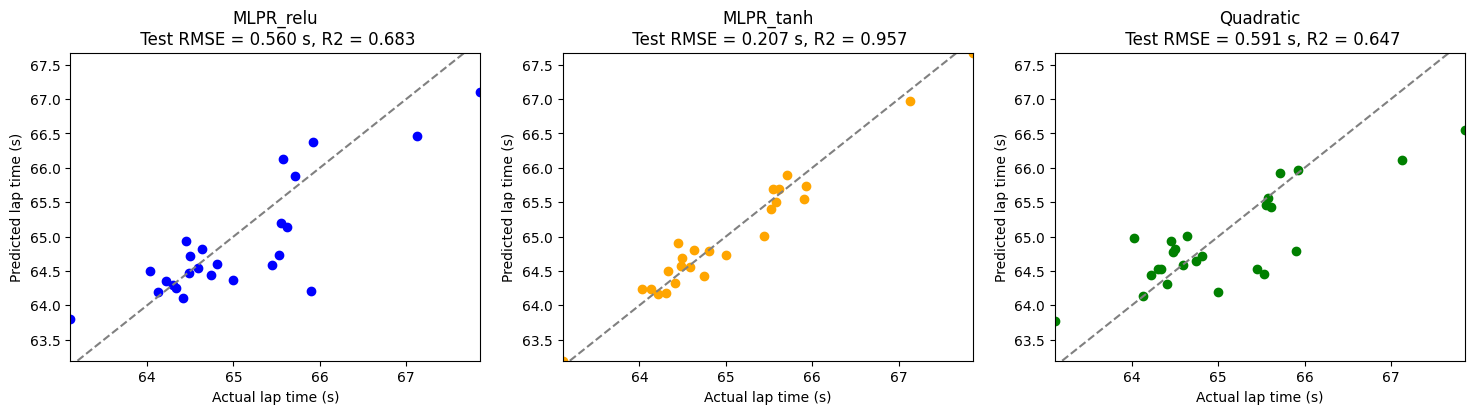

In [656]:
# Plot of actual vs predicted for each fitted model on testing data
fig, axes = plt.subplots(1, 3, figsize=(18, 4))

x_low, x_high = y_test_nn.min(), y_test_nn.max()
y_low = min(yhat_relu_test.min(), yhat_tanh_test.min(), yhat_quad_test_nn.min() )
y_high = max(yhat_relu_test.max(), yhat_tanh_test.max(), yhat_quad_test_nn.max())

plots = [(axes[0], yhat_relu_test, "MLPR_relu",
     relu_nn['test_RMSE_s'].iloc[0], relu_nn['test_R2'].iloc[0], "blue"),
    (axes[1], yhat_tanh_test, "MLPR_tanh",
    tanh_nn['test_RMSE_s'].iloc[0], tanh_nn['test_R2'].iloc[0], "orange"),
    (axes[2], yhat_quad_test_nn, "Quadratic",
    quad_nn['test_RMSE_s'].iloc[0], quad_nn['test_R2'].iloc[0], "green")]

for ax, prediction, name, rmse, r2, color in plots:
    ax.scatter(y_test_nn, np.asarray(prediction).ravel(), color=color)
    ax.axline((0,0), slope=1, linestyle="--", color="grey")
    ax.set_xlabel("Actual lap time (s)")
    ax.set_ylabel("Predicted lap time (s)")
    ax.set_title(f"{name}\n Test RMSE = {rmse:.3f} s, R2 = {r2:.3f}")
    ax.set_xlim(x_low, x_high)
    ax.set_ylim(y_low, y_high)

plt.savefig("mgfreita_pr03_laptime_validation.png")

In [605]:
# Create normalized grid
fuel = df_laptime['fuel_kg']
tire = df_laptime['tire_age_laps']
fuel_values = np.linspace(fuel.min(), fuel.max(), 50)
tire_values = np.linspace(tire.min(), tire.max(), 50)
fuel_grid, tire_grid = np.meshgrid(fuel_values, tire_values)
X_grid_nn = np.column_stack((fuel_grid.ravel(), tire_grid.ravel()))
X_grid_nn_normalized = (X_grid_nn - X_min_nn) / (X_max_nn - X_min_nn)

In [606]:
# Predict on normalized grid
relu_surf = model_relu.predict(X_grid_nn_normalized).reshape(fuel_grid.shape)
tanh_surf = model_tanh.predict(X_grid_nn_normalized).reshape(fuel_grid.shape)
quad_surf = predict_quad(X_train_nn_normalized, y_train_nn, X_grid_nn_normalized).reshape(fuel_grid.shape)

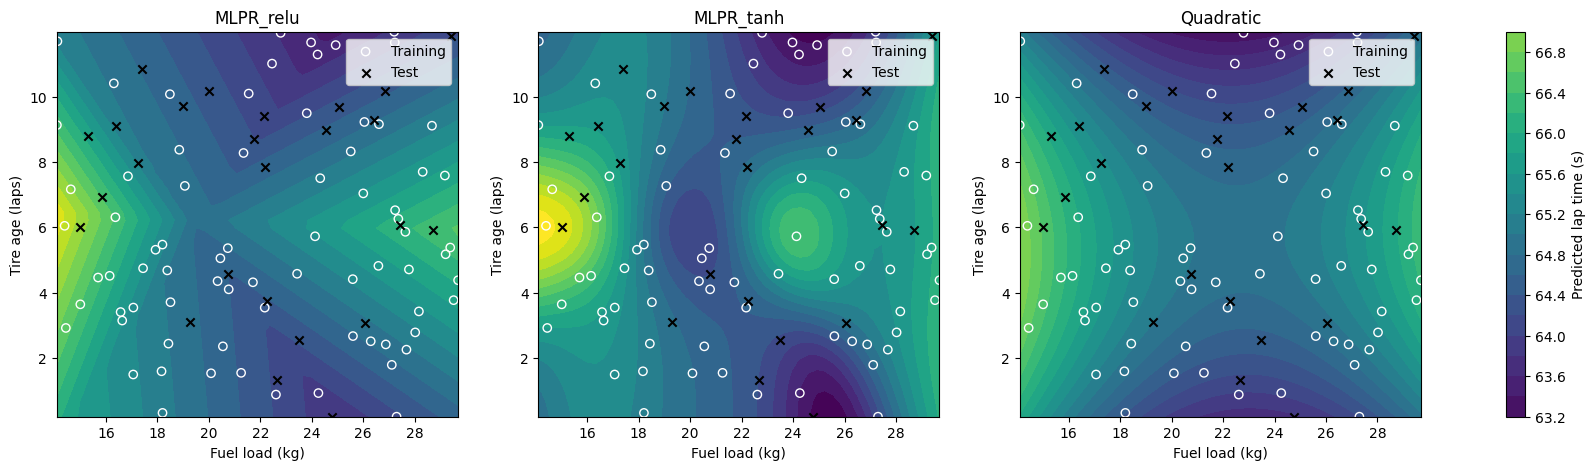

In [607]:
color_min = min(relu_surf.min(), tanh_surf.min(), quad_surf.min())
color_max = max(relu_surf.max(), tanh_surf.max(), quad_surf.max())

fig, axes = plt.subplots(1, 3, figsize=(22, 5))

surfaces = [(axes[0], relu_surf, "MLPR_relu"),
            (axes[1], tanh_surf, "MLPR_tanh"),
            (axes[2], quad_surf, "Quadratic")]

for ax, surface, title in surfaces:
    contour = ax.contourf(fuel_grid, tire_grid, surface, levels=20, vmin=color_min, vmax=color_max)
    ax.scatter(df_laptime_train["fuel_kg"], df_laptime_train["tire_age_laps"], marker="o", facecolors="none", edgecolors="white", label="Training")
    ax.scatter(df_laptime_test["fuel_kg"], df_laptime_test["tire_age_laps"], marker="x", color="black", label="Test")
    ax.set_xlabel("Fuel load (kg)")
    ax.set_ylabel("Tire age (laps)")
    ax.set_title(title)
    ax.legend(loc="upper right")

fig.colorbar(contour, ax=axes, label="Predicted lap time (s)")
plt.savefig("mgfreita_pr03_laptime_surfaces.png")
plt.show()

The ReLU activation function is piecewise linear, while tanh is a smooth function, which is reflected in the surfaces from the plot. In this particular split of the data, the smoother surface of the tanh activation function is the one that has the lowest RMSE and predicts better. However, this might depend on the initial splitting of the dataset. The number of hidden layers, neurons and activation functions are hyperparameters, while the learned weights are the coefficients obtained from fitting the model.